# 언어모델&생성모델 과제

# 1. 언어모델

## BERT — Masked Language Modeling

BERT는 Transformer **인코더** 기반의 언어모델로, `[MASK]` 앞뒤 문맥을 활용해 가려진 토큰을 예측합니다.

### 1-1. BERT 모델과 tokenizer 불러오기

In [2]:
from transformers import BertTokenizer, BertForMaskedLM
import torch

# BERT 모델과 tokenizer 초기화
tokenizer = BertTokenizer.from_pretrained('klue/bert-base') # base : 모델크기, (uncased : 소문자 학습)
model = BertForMaskedLM.from_pretrained('klue/bert-base') # base : 모델크기, (uncased : 소문자 학습)
# tokenizer : raw text를 개별 토큰으로 분리(Wordpiece). 토크나이저 사전에 따라 고유한 정수 인덱스(고정값)를 매핑함.

# tokenizer를 통해 생성된 정수 인덱스 : 텍스트를 모델이 읽을 수 있도록 숫자화
# Embedding vector : 단어의 의미적, 문맥적 특성을 모델링
model.eval()  # 사전학습된 가중치로 추론할 때 평가 모드 사용


tokenizer_config.json:   0%|          | 0.00/289 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/248k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/495k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/425 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  445MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: klue/bert-base
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BertForMaskedLM(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(32000, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12, el

### 1-2. 문장을 토큰화하고 `[MASK]` 위치 확인하기

In [3]:
# 테스트할 문장
text = "[CLS] 열여덟, 우리는 서로의 이름을 처음 불렀다. 그리고 스물 하나, 우린 [MASK]을 했다.[SEP]"

# 문장을 토큰으로 변환
tokenized_text = tokenizer.tokenize(text) # text(문장)을 토큰으로 변환해 tokenized_text에 저장합시다!
indexed_tokens = tokenizer.convert_tokens_to_ids(tokenized_text) # 토큰을 index로 변환하는 코드!

print(tokenized_text) # 토큰이 출력됩니다.
print(indexed_tokens) # 인덱스가 출력됩니다.

# 마스킹된 위치 찾기
masked_index = tokenized_text.index("[MASK]") # 토큰화된 결과물에서 index 메서드를 통해 [MASK]의 위치를 확인해봅시다!
print(masked_index)

['[CLS]', '열', '##여', '##덟', ',', '우리', '##는', '서로', '##의', '이름', '##을', '처음', '불렀', '##다', '.', '그리고', '스물', '하나', ',', '우린', '[MASK]', '을', '했', '##다', '.', '[SEP]']
[2, 1432, 2173, 3542, 16, 3616, 2259, 4084, 2079, 3934, 2069, 3790, 6895, 2062, 18, 3673, 10514, 3657, 16, 8983, 4, 1498, 1902, 2062, 18, 3]
20


### 1-3. 텐서로 변환하고 `[MASK]` 토큰 예측하기

In [4]:
# 앞에서 만든 정수 ID 목록을 PyTorch 텐서로 변환합니다.
tokens_tensor = torch.tensor([indexed_tokens])

with torch.no_grad():
    outputs = model(tokens_tensor)
    predictions = outputs.logits

# 전체 logits를 출력하면 매우 길어지므로 차원만 출력합니다.
print("Logits shape:", tuple(predictions.shape))

Logits shape: (1, 26, 32000)


In [5]:
# 예측된 토큰 확인
masked_tokens_before = tokenized_text.copy()
predicted_index = torch.argmax(predictions[0, masked_index]).item() # masked_index에 들어갈 것으로 가장 확률이 높은 인덱스
predicted_token = tokenizer.convert_ids_to_tokens([predicted_index])[0]

# 예측된 토큰으로 마스크 채우기
tokenized_text[masked_index] = predicted_token
# 토큰화된 텍스트를 다시 문자열로 변환
filled_text = tokenizer.convert_tokens_to_string(tokenized_text[1:-1])

print("Original:", text)
print("Masked:", masked_tokens_before)
print("Predicted token:", predicted_token) ; print()

print("Filled sentence:", filled_text)

Original: [CLS] 열여덟, 우리는 서로의 이름을 처음 불렀다. 그리고 스물 하나, 우린 [MASK]을 했다.[SEP]
Masked: ['[CLS]', '열', '##여', '##덟', ',', '우리', '##는', '서로', '##의', '이름', '##을', '처음', '불렀', '##다', '.', '그리고', '스물', '하나', ',', '우린', '[MASK]', '을', '했', '##다', '.', '[SEP]']
Predicted token: 사랑

Filled sentence: 열여덟, 우리는 서로의 이름을 처음 불렀다. 그리고 스물 하나, 우린 사랑 을 했다.


### 1-4. 직접 만든 문장에서도 `[MASK]` 예측하기

`fill_mask()` 함수로 두 문장의 예측 결과를 비교해 봅시다. 문장 하나는 직접 바꾸어도 좋습니다.

In [6]:
def fill_mask(input_text):
    # 텍스트를 토큰으로 변환
    tokenized_text = tokenizer.tokenize(input_text)
    indexed_tokens = tokenizer.convert_tokens_to_ids(tokenized_text)

    # 마스킹된 위치 찾기
    masked_index = tokenized_text.index("[MASK]") # 토큰화된 텍스트에서 마스킹된 위치를 찾아봅시다!

    # 토큰화된 텍스트 -> 정수인덱스(ID) -> Pytorch 텐서
    tokens_tensor = torch.tensor([indexed_tokens])

    # 모델에 토큰 텐서를 전달하고 예측 수행
    with torch.no_grad():
        outputs = model(tokens_tensor)
        predictions = outputs[0]

    # 예측된 토큰 확인
    predicted_index = torch.argmax(predictions[0, masked_index]).item() # 위 코드 참고! masked_index에 들어갈 것으로 가장 확률이 높은 인덱스
    predicted_token = tokenizer.convert_ids_to_tokens([predicted_index])[0]

    # 마스크를 채운 문장 반환
    tokenized_text[masked_index] = predicted_token # 토큰화된 텍스트의 마스킹된 위치(인덱스 사용)를 예측된 토큰으로 채워봅시다!
    return tokenizer.convert_tokens_to_string(tokenized_text[1:-1])

In [7]:
# 예시 1: "[CLS] 열여덟, 우리는 서로의 이름을 처음 불렀다. 그리고 스물 하나, 우린 [MASK]을 했다.[SEP]"
# 예시 2: "[CLS] 권유철은 INSIGHT 학회를 정말 사랑한다. 그는 INSIGHT 학회를 위해 [MASK]를 했다.[SEP]"

input_text = "[CLS] 권유철은 INSIGHT 학회를 정말 사랑한다. 그는 INSIGHT 학회를 위해 [MASK]을 했다.[SEP]"
# 입력문을 두 개 준비해 비교해 봅시다. input_text_2는 직접 수정하세요.
input_text_2 = "[CLS] 오늘 본 영화는 정말 [MASK]한 영화였다.[SEP]"
for i, sentence in enumerate([input_text, input_text_2], 1):
    filled_text = fill_mask(sentence)
    print(f"문장 {i}: {sentence}")
    print(f"복원 {i}: {filled_text}")

문장 1: [CLS] 권유철은 INSIGHT 학회를 정말 사랑한다. 그는 INSIGHT 학회를 위해 [MASK]을 했다.[SEP]
복원 1: 권유철은 INSIGHT 학회를 정말 사랑한다. 그는 INSIGHT 학회를 위해 헌신 을 했다.
문장 2: [CLS] 오늘 본 영화는 정말 [MASK]한 영화였다.[SEP]
복원 2: 오늘 본 영화는 정말 핫 한 영화였다.


## RAG · LangChain · LangGraph

아래 공통 문서로 검색과 답변 생성을 실습합니다.

### 2-1. 라이브러리 설치 및 API 키 입력

In [8]:
# Colab에서 LangGraph · Chroma · Google Gemini 관련 패키지 설치
%pip -q install "langchain-google-genai>=4,<5" "langgraph>=1,<2" "langchain-chroma>=1,<2" "chromadb>=1,<2"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.2 which is incompatible.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 4.0.0 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 4.0.0 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.3.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=

In [9]:
import os
from getpass import getpass

# Gemini API 키는 화면에 표시되거나 노트북에 저장되지 않도록 입력합니다.
os.environ["GOOGLE_API_KEY"] = getpass("Gemini API 키 입력: ").strip()
if not os.environ["GOOGLE_API_KEY"]:
    raise ValueError("Gemini API 키를 입력해야 RAG 실습을 진행할 수 있습니다.")

Gemini API 키 입력: ··········


### 2-2. 검색할 문서

강의자료의 BERT·AE·VAE·GAN·Diffusion 내용을 정리한 문서입니다.

In [10]:
from langchain_core.documents import Document

# 강의자료의 개념을 짧게 요약한 공통 자료입니다.
lecture_docs = [
    Document(
        page_content=(
            "BERT는 Transformer 인코더 기반 언어모델이며, 문장의 양방향 문맥을 학습한다. "
            "MLM(Masked Language Model)은 일부 토큰을 가리고 앞뒤 문맥을 이용하여 원래 토큰을 예측한다. "
            "BERT의 주요 활용에는 문장 분류, 감성 분석, 질의응답 등이 있다."
        ),
        metadata={"source": "강의 요약 1 — BERT"},
    ),
    Document(
        page_content=(
            "AE(Autoencoder)는 입력 이미지를 잠재 벡터로 압축한 뒤 복원하며, 입력과 복원 이미지의 차이를 줄이도록 학습한다. "
            "그러나 AE의 잠재공간은 불규칙하게 형성될 수 있어 임의의 벡터로 새로운 이미지를 생성하기 어렵다. "
            "VAE는 각 입력을 평균과 분산을 갖는 확률분포로 나타낸다. "
            "재매개변수화 z = μ + σ·ε를 사용하며, 복원 오차와 KL 발산을 함께 고려하여 학습한다. "
            "이를 통해 잠재공간을 보다 규칙적으로 구성하고 새로운 데이터를 생성할 수 있다."
        ),
        metadata={"source": "강의 요약 2 — AE와 VAE"},
    ),
    Document(
        page_content=(
            "GAN은 노이즈로부터 가짜 이미지를 만드는 생성자와 진짜·가짜를 구분하는 판별자가 경쟁하며 학습한다. "
            "GAN은 생성자와 판별자 사이의 학습 불균형, 모드 붕괴 등의 한계가 있다. "
            "확산 모델은 순확산 단계에서 이미지에 가우시안 노이즈를 점차 추가한다. "
            "역확산에서는 학습된 신경망이 노이즈를 단계적으로 제거하여 새로운 이미지를 생성한다. "
            "따라서 순확산 이미지의 노이즈 증가만 관찰했다고 새로운 이미지가 생성된 것은 아니다."
        ),
        metadata={"source": "강의 요약 3 — GAN과 확산모델"},
    ),
]
print("공통 문서 수:", len(lecture_docs))
for document in lecture_docs:
    print("-", document.metadata["source"])

공통 문서 수: 3
- 강의 요약 1 — BERT
- 강의 요약 2 — AE와 VAE
- 강의 요약 3 — GAN과 확산모델


### 2-3. 임베딩을 이용한 문서 검색 준비

In [11]:
from langchain_google_genai import GoogleGenerativeAIEmbeddings
from langchain_chroma import Chroma

# 질문과 문서를 벡터 형태로 표현하고 관련 문서를 찾습니다.
embeddings = GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-001")
vectordb = Chroma.from_documents(
    documents=lecture_docs,
    ids=[d.metadata["source"] for d in lecture_docs],
    embedding=embeddings,
    collection_name="insight_lecture_rag",
)
retriever = vectordb.as_retriever(search_kwargs={"k": 2})
print("검색 준비 완료")

검색 준비 완료


### 2-4. 검색 결과를 활용한 답변 생성

In [12]:
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite", temperature=0)

PROMPT = ChatPromptTemplate.from_template("""아래 [강의 요약 문서]의 내용만 근거로 질문에 한국어로 답하세요.
문서에 없는 내용은 추측하지 말고 확인할 수 없다고 말하세요.
답변 끝에 참조한 문서 제목을 표시하세요.

[질문]
{question}

[강의 요약 문서]
{context}
""")
rag_chain = PROMPT | llm | StrOutputParser()

### 2-5. LangGraph: 검색 → 답변 생성

In [13]:
from typing import TypedDict, List
from langgraph.graph import StateGraph, END

# 검색 결과를 출처와 함께 LLM에 전달할 문자열로 변환합니다.
def format_docs(documents):
    return "\n\n".join(
        f"[{d.metadata['source']}]\n{d.page_content}" for d in documents
    )

class QAState(TypedDict):
    question: str
    retrieved: List[Document]
    answer: str

def node_retrieve(state: QAState):
    return {"retrieved": retriever.invoke(state["question"])}

def node_generate(state: QAState):
    context = format_docs(state["retrieved"])
    answer = rag_chain.invoke({"question": state["question"], "context": context})
    return {"answer": answer}

workflow = StateGraph(QAState)
workflow.add_node("retrieve", node_retrieve)
workflow.add_node("generate", node_generate)
workflow.set_entry_point("retrieve")
workflow.add_edge("retrieve", "generate")
workflow.add_edge("generate", END)
app = workflow.compile()

### 2-6. 강의 요약 문서를 검색하여 답변 확인하기

In [14]:
# 강의 요약 문서 중 관련된 내용을 검색하여 답변을 생성합니다.
question = "이번 강의에서 AE와 VAE의 차이를 어떻게 설명했으며, VAE는 왜 새로운 데이터를 생성할 수 있나요?"
result = app.invoke({"question": question})
print("▼ 검색된 문서")
for doc in result["retrieved"]:
    print("-", doc.metadata["source"])
print("\n▼ RAG 답변")
print(result["answer"])


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


▼ 검색된 문서
- 강의 요약 2 — AE와 VAE
- 강의 요약 3 — GAN과 확산모델

▼ RAG 답변
강의 요약 문서에 따르면, AE(Autoencoder)와 VAE의 차이는 잠재공간의 특성에 있습니다. AE는 입력 이미지를 잠재 벡터로 압축한 뒤 복원하며, 잠재공간이 불규칙하게 형성될 수 있어 임의의 벡터로 새로운 이미지를 생성하기 어렵습니다. 반면 VAE는 각 입력을 평균과 분산을 갖는 확률분포로 나타내고, 복원 오차와 KL 발산을 함께 고려하여 학습함으로써 잠재공간을 보다 규칙적으로 구성합니다. 

VAE가 새로운 데이터를 생성할 수 있는 이유는 이러한 과정을 통해 잠재공간이 보다 규칙적으로 구성되기 때문입니다.

참조 문서: [강의 요약 2 — AE와 VAE]


# 2. 생성모델

Fashion MNIST 이미지를 사용해 AE·VAE·GAN·Diffusion을 실습합니다.

## 공통 라이브러리

In [15]:
import matplotlib.pyplot as plt
import numpy as np

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Model

import torch

## 1. AE — 이미지 압축과 복원

입력 이미지를 압축하고 복원하도록 학습합니다.

In [16]:
## Fashion MNIST 데이터 로드
(x_train, _), (x_test, _) = tf.keras.datasets.fashion_mnist.load_data()

# 정규화 및 reshape
x_train = x_train.astype('float32')/255.
x_test = x_test.astype('float32')/255.
x_train = x_train.reshape((-1, 28, 28, 1))      #reshape()를 호출해 훈련데이터를 (배치크기, 28, 28, 1)로 설정합니다.
x_test = x_test.reshape((-1, 28, 28, 1))


print("훈련 데이터:", x_train.shape)
print("테스트 데이터:", x_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
훈련 데이터: (60000, 28, 28, 1)
테스트 데이터: (10000, 28, 28, 1)


In [17]:
# Conv2D 기반 오토인코더 구조입니다.
# 인코더: Conv2D + MaxPooling2D 로 특징 추출
# 디코더: Conv2D + UpSampling2D 로 이미지 복원
input_img = tf.keras.layers.Input(shape=(28, 28, 1))

# 인코더
x = tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
x = tf.keras.layers.MaxPooling2D((2, 2), padding='same')(x)
x = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
encoded = tf.keras.layers.MaxPooling2D((2, 2), padding='same')(x)

# 디코더
x = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same')(encoded)
x = tf.keras.layers.UpSampling2D((2, 2))(x)
x = tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same')(x)
x = tf.keras.layers.UpSampling2D((2, 2))(x)
decoded = tf.keras.layers.Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)  # 출력 픽셀값을 [0,1]로 제한하기 위해 sigmoid 사용 (입력 데이터 정규화가 [0,1]인 경우)

autoencoder = tf.keras.Model(input_img, decoded)

#모델컴파일. 먼저 화소당 MSE손실을 사용하고, optimizer로 'adam'을 사용합니다.
autoencoder.compile(optimizer='adam', loss=tf.keras.losses.MeanSquaredError())

### AE 학습 및 결과 시각화

Epoch 1/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 45s 937ms/step - loss: 0.1531 - val_loss: 0.1074
Epoch 2/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 117ms/step - loss: 0.0655 - val_loss: 0.0431
Epoch 3/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - loss: 0.0369 - val_loss: 0.0330
Epoch 4/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 0.0330 - val_loss: 0.0313
Epoch 5/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - loss: 0.0290 - val_loss: 0.0284
Epoch 6/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step - loss: 0.0265 - val_loss: 0.0259
Epoch 7/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step - loss: 0.0245 - val_loss: 0.0241
Epoch 8/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0229 - val_loss: 0.0231
Epoch 9/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0217 - val_loss: 0.0216
Epoch 10/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0205 - val_loss: 0.0205
Epoch 11/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0195 - val_loss: 0.0196
Epoch 12/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0187 - val_loss: 0.0

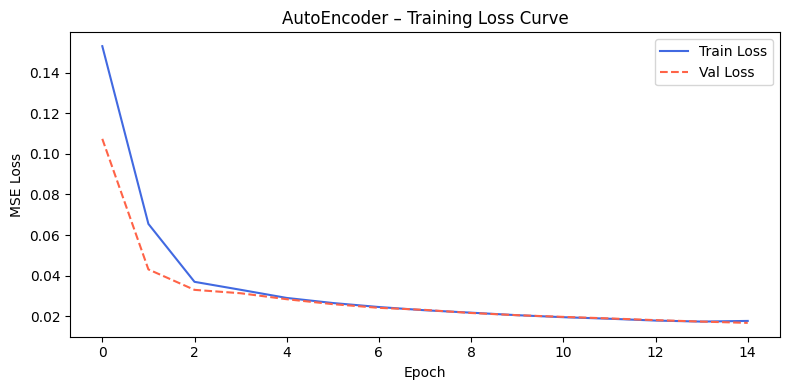

In [18]:
history = autoencoder.fit(
    x_train[:2048], x_train[:2048],       # AE는 입력과 정답 모두 원본 이미지입니다.
    epochs=15,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test[:256], x_test[:256]),
    verbose=1
)

# AE 학습 수렴 곡선
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'],     label='Train Loss', color='royalblue')
plt.plot(history.history['val_loss'], label='Val Loss',   color='tomato', linestyle='--')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.title('AutoEncoder – Training Loss Curve')
plt.legend(); plt.tight_layout(); plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


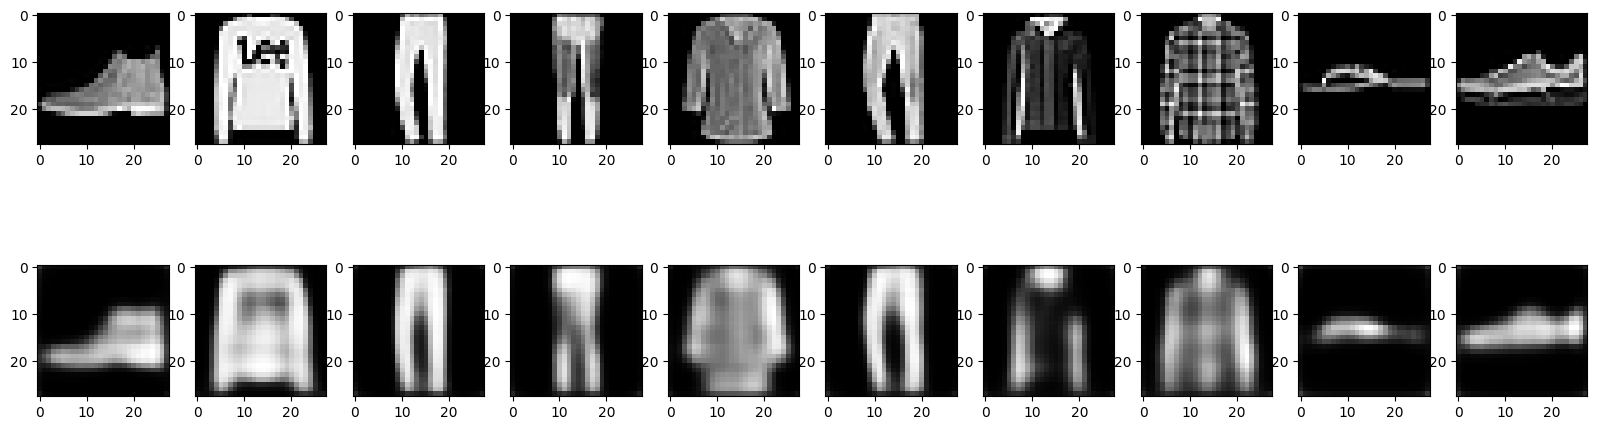

In [19]:
decoded_imgs = autoencoder.predict(x_test[:10])  # 어떤데이터를 예측해야할까요?

n=10
plt.figure(figsize=(20, 6))
for i in range(n):
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28,28), cmap='gray')    #원본이미지

    ax = plt.subplot(2, n, i + n + 1)
    plt.imshow(decoded_imgs[i].reshape(28,28), cmap='gray')   # 재구성된 이미지
plt.show()

#### AE — 원본과 복원 이미지 해석

위의 **원본 이미지(첫째 줄)와 복원 이미지(둘째 줄)**를 비교하세요. 복원 결과에서 유지된 특징과 흐릿해진 특징을 각각 하나씩 찾고, AE가 **압축 후 복원**하는 이유를 강의 내용과 연결해 2~3문장으로 설명하세요.

**[답안]**

관찰한 차이 및 해석:형태는 유지되었는데 색상의 경계나 글씨, 무늬 같은 디테일한 부분이 흐릿해졌다. AE는 데이터를 저차원으로 압축하고 복원하는 과정에서 오차를 줄이기 위해 핵심 특징만 우선으로 학습할 수 있게 된다.


## 2. VAE — 확률적 잠재벡터와 학습

인코더가 예측한 평균과 로그분산으로 잠재벡터를 샘플링하고, 복원 손실과 KL 발산을 함께 최소화해 봅니다.

In [20]:
latent_dim = 32  # 잠재 공간 차원 (Fashion MNIST의 복잡도를 반영해 32로 설정)

# ----- 인코더 -----
encoder_inputs = layers.Input(shape=(28, 28, 1))
x = layers.Conv2D(32, 3, activation="relu", strides=2, padding="same")(encoder_inputs)
x = layers.Conv2D(64, 3, activation="relu", strides=2, padding="same")(x)
x = layers.Flatten()(x)
x = layers.Dense(128, activation="relu")(x)
z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)

### 재매개변수화와 디코더

`z = μ + σ·ε`를 이용하여 잠재벡터를 샘플링합니다.

In [21]:
# 재매개변수화 트릭


def sampling(args):
    z_mean, z_log_var = args      #z의 평균과 로그분산을 샘플링합니다!
    eps = tf.random.normal(shape=tf.shape(z_mean))   # 무작위성을 줍시다! 무작위는영어로?
    return z_mean + tf.exp(0.5 * z_log_var) * eps   # return값이 잠재벡터 z의 공식이 됩니다.

z = layers.Lambda(sampling, name="z")([z_mean, z_log_var])
encoder = Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder")
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 14, 14,    │        320 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 7, 7, 64)  │     18,496 │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 3136)      │          0 │ conv2d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │    401,536 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 32)        │      4,128 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 32)        │      4,128 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z (Lambda)          │ (None, 32)        │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 428,608 (1.64 MB)

 Trainable params: 428,608 (1.64 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
# ----- 디코더 -----
latent_inputs = layers.Input(shape=(latent_dim,))
x = layers.Dense(7 * 7 * 128, activation="relu")(latent_inputs)
x = layers.Reshape((7, 7, 128))(x)
x = layers.Conv2DTranspose(128, 3, activation="relu", strides=2, padding="same")(x)
x = layers.Conv2DTranspose(64, 3, activation="relu", strides=2, padding="same")(x)
decoder_outputs = layers.Conv2D(1, 3, activation="sigmoid", padding="same")(x)
decoder = Model(latent_inputs, decoder_outputs, name="decoder")  # 디코더의 입력과 출력 변수를 넣어주세요!
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6272)           │       206,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 128)    │       147,584 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 1)      │           577 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 428,929 (1.64 MB)

 Trainable params: 428,929 (1.64 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
z_mu, z_lv, z_sample = encoder(x_test[:1])
print("잠재 벡터 평균 shape:", z_mu.shape)
print("샘플링 잠재 벡터 shape:", z_sample.shape)

# 같은 입력에서 샘플링을 한 번 더 수행하면 값이 달라지는지 확인해 봅시다.
_, _, z_sample_second = encoder(x_test[:1])
print("두 잠재 벡터의 shape:", z_sample.shape, z_sample_second.shape)
print("두 샘플의 평균 절댓값 차이:", float(tf.reduce_mean(tf.abs(z_sample - z_sample_second))))

잠재 벡터 평균 shape: (1, 32)
샘플링 잠재 벡터 shape: (1, 32)
두 잠재 벡터의 shape: (1, 32) (1, 32)
두 샘플의 평균 절댓값 차이: 1.2883368730545044


### VAE 학습 및 이미지 생성

Epoch 1/10 | total=108.59 | reconstruction=108.45 | KL=0.14
Epoch 2/10 | total=75.73 | reconstruction=72.86 | KL=2.88
Epoch 3/10 | total=61.79 | reconstruction=57.76 | KL=4.03
Epoch 4/10 | total=55.80 | reconstruction=51.45 | KL=4.34
Epoch 5/10 | total=53.65 | reconstruction=49.21 | KL=4.44
Epoch 6/10 | total=51.60 | reconstruction=46.73 | KL=4.87
Epoch 7/10 | total=49.80 | reconstruction=44.52 | KL=5.29
Epoch 8/10 | total=48.48 | reconstruction=42.96 | KL=5.52
Epoch 9/10 | total=46.19 | reconstruction=40.34 | KL=5.85
Epoch 10/10 | total=42.23 | reconstruction=35.79 | KL=6.45


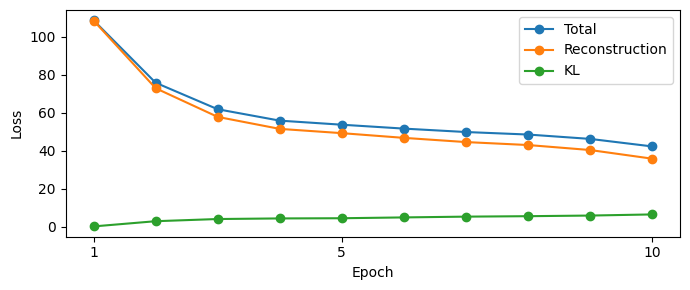

In [24]:
# VAE 학습: 복원 오차와 KL 발산을 함께 최소화합니다.
vae_optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
vae_dataset = tf.data.Dataset.from_tensor_slices(x_train[:2048]).shuffle(2048).batch(128)

@tf.function
def vae_train_step(images):
    with tf.GradientTape() as tape:
        z_mu, z_lv, z_sampled = encoder(images, training=True)
        reconstructed = decoder(z_sampled, training=True)
        reconstruction_loss = tf.reduce_mean(
            tf.reduce_sum(tf.square(images - reconstructed), axis=[1, 2, 3])
        )
        kl_loss = -0.5 * tf.reduce_mean(
            tf.reduce_sum(1 + z_lv - tf.square(z_mu) - tf.exp(z_lv), axis=1)
        )
        total_loss = reconstruction_loss + kl_loss

    variables = encoder.trainable_variables + decoder.trainable_variables
    gradients = tape.gradient(total_loss, variables)
    vae_optimizer.apply_gradients(zip(gradients, variables))
    return total_loss, reconstruction_loss, kl_loss

vae_history = {'total': [], 'reconstruction': [], 'kl': []}
VAE_EPOCHS = 10
for epoch in range(VAE_EPOCHS):
    losses = []
    for images in vae_dataset:
        losses.append(vae_train_step(images))
    mean_losses = tf.reduce_mean(tf.stack(losses), axis=0).numpy()
    for key, value in zip(vae_history, mean_losses):
        vae_history[key].append(float(value))
    print(f"Epoch {epoch + 1}/{VAE_EPOCHS} | total={mean_losses[0]:.2f} | "
          f"reconstruction={mean_losses[1]:.2f} | KL={mean_losses[2]:.2f}")

plt.figure(figsize=(7, 3))
for key, label in [('total', 'Total'), ('reconstruction', 'Reconstruction'), ('kl', 'KL')]:
    plt.plot(range(1, VAE_EPOCHS + 1), vae_history[key], marker='o', label=label)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks([1, 5, 10])
plt.legend()
plt.tight_layout()
plt.show()

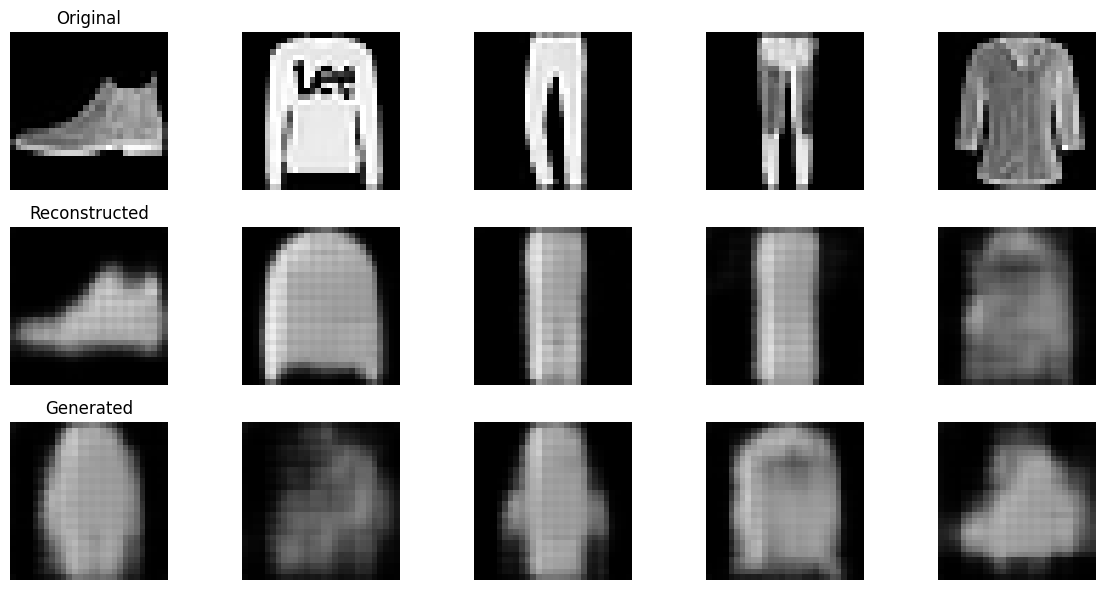

In [25]:
# 학습된 VAE의 복원과 새로운 이미지 생성 결과를 비교합니다.
original = x_test[:5]
_, _, latent_samples = encoder(original, training=False)
reconstructed = decoder(latent_samples, training=False).numpy()
new_latent = tf.random.normal(shape=(5, latent_dim))
generated = decoder(new_latent, training=False).numpy()

plt.figure(figsize=(12, 6))
for i in range(5):
    for row, imgs, label in [(0, original, 'Original'),
                             (1, reconstructed, 'Reconstructed'),
                             (2, generated, 'Generated')]:
        ax = plt.subplot(3, 5, row * 5 + i + 1)
        ax.imshow(imgs[i, :, :, 0], cmap='gray', vmin=0, vmax=1)
        ax.axis('off')
        if i == 0:
            ax.set_title(label)
plt.tight_layout()
plt.show()

#### VAE — 학습과 이미지 생성 결과 해석

학습 손실과 원본·복원·생성 이미지의 차이를 확인하세요. VAE에서 복원 손실과 KL 발산을 함께 사용하는 이유를 설명하고, `z = μ + σ·ε`의 역할을 연결해 작성하세요.

**[답안]**

복원 이미지는 AE에 비해 흐릿하고 형태만 남아 있는 상태이고, 생성 이미지는 형태는 보이지만 경계가 모호하다. VAE는 출력이 입력과 비슷해지도록 학습하는 동시에 KL 발산을 줄여 분포가 표준정규분포에 가까워지도록 학습한다. 이를 통해서 잠재공간이 규칙적으로 형성된다. 이때 z = μ + σ·ε는 무작위성을 노이즈 변수 ε로 분리함으로써 샘플링 과정이 있어도 신경망을 학습할 수 있도록 한다.

## 3. GAN — 생성자와 판별자 학습

생성자와 판별자를 20에폭 동안 번갈아 학습하고 손실과 생성 이미지를 비교합니다.

In [26]:
# Fashion MNIST 데이터 로드
(x_train, _), (_, _) = tf.keras.datasets.fashion_mnist.load_data()

# [0, 1] → [-1, 1] 스케일링 (GAN에서는 tanh 출력 맞추기 위함)
x_train = (x_train.astype(np.float32) - 127.5) / 127.5
x_train = np.expand_dims(x_train, axis=-1)

BUFFER_SIZE = 60000
BATCH_SIZE = 32

# tf.data로 배치 구성
train_dataset = tf.data.Dataset.from_tensor_slices(x_train[:1024]).shuffle(1024).batch(BATCH_SIZE)

In [27]:
def make_generator_model():
    model = tf.keras.Sequential([
        layers.Dense(7*7*256, use_bias=False, input_shape=(100,)),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Reshape((7, 7, 256)),

        layers.Conv2DTranspose(128, (5, 5), strides=(1, 1), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(1, (5, 5), strides=(2, 2), padding='same', use_bias=False, activation='tanh')
    ])
    return model

generator = make_generator_model()  #위에서 정의한 생성자 함수!
generator.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_4              │ (None, 28, 28, 1)      │         1,600 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,944 (8.89 MB)

 Trainable params: 2,305,472 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

In [28]:
def make_discriminator_model():
    model = tf.keras.Sequential([
        layers.Conv2D(64, (5, 5), strides=(2, 2), padding='same',
                      input_shape=[28, 28, 1]),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(128, (5, 5), strides=(2, 2), padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(1)
    ])
    return model

discriminator = make_discriminator_model()  #위에서 정의한 판별자 함수!
discriminator.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
# 손실 함수 정의
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def generator_loss(fake_output):
    # 생성자는 판별자를 '진짜'라고 속여야 하므로 레이블 = 1
    return cross_entropy(tf.ones_like(fake_output), fake_output)

def discriminator_loss(real_output, fake_output):
    # 판별자는 진짜=1, 가짜=0 으로 분류해야 함
    real_loss = cross_entropy(tf.ones_like(real_output),  real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss        # 총 손실은 두 손실의 합입니다!

# GAN 학습 안정화를 위해 beta_1=0.5 사용 (일반적인 GAN 권장 설정)
generator_optimizer     = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)

noise_dim = 100
num_examples_to_generate = 16

# 고정 시드(매번 같은 예시 생성)
seed = tf.random.normal([num_examples_to_generate, noise_dim])

@tf.function
def train_step(images):
    noise = tf.random.normal([BATCH_SIZE, noise_dim])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

    return gen_loss, disc_loss

Epoch 1/20 | Generator Loss: 0.6042 | Discriminator Loss: 1.1913
Epoch 2/20 | Generator Loss: 0.6190 | Discriminator Loss: 1.2289
Epoch 3/20 | Generator Loss: 0.7277 | Discriminator Loss: 1.1879
Epoch 4/20 | Generator Loss: 0.7475 | Discriminator Loss: 1.1835
Epoch 5/20 | Generator Loss: 0.8140 | Discriminator Loss: 1.1991
Epoch 6/20 | Generator Loss: 0.5894 | Discriminator Loss: 1.4926
Epoch 7/20 | Generator Loss: 0.6467 | Discriminator Loss: 1.4787
Epoch 8/20 | Generator Loss: 0.7093 | Discriminator Loss: 1.3999
Epoch 9/20 | Generator Loss: 0.7234 | Discriminator Loss: 1.3118
Epoch 10/20 | Generator Loss: 0.7492 | Discriminator Loss: 1.2493
Epoch 11/20 | Generator Loss: 0.6745 | Discriminator Loss: 1.4323
Epoch 12/20 | Generator Loss: 0.7300 | Discriminator Loss: 1.3340
Epoch 13/20 | Generator Loss: 0.7793 | Discriminator Loss: 1.3163
Epoch 14/20 | Generator Loss: 0.6547 | Discriminator Loss: 1.3537
Epoch 15/20 | Generator Loss: 0.6771 | Discriminator Loss: 1.3660
Epoch 16/20 | Gener

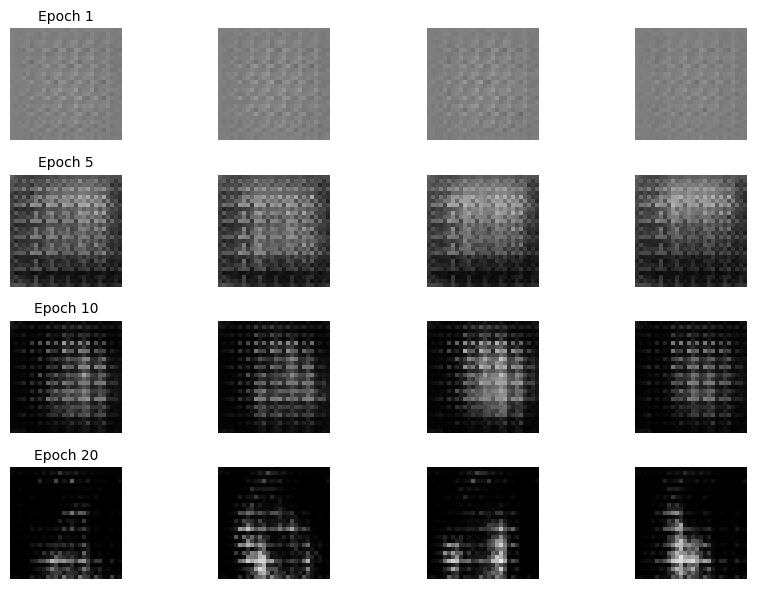

In [31]:
# 고정된 노이즈로 학습에 따른 생성 이미지 변화를 비교합니다.
GAN_EPOCHS = 20
snapshots = {}
snapshot_epochs = [1, 5, 10, 20]
gan_history = {'generator': [], 'discriminator': []}

for epoch in range(GAN_EPOCHS):
    gen_losses, disc_losses = [], []
    for images in train_dataset.take(16):
        gen_loss, disc_loss = train_step(images)
        gen_losses.append(float(gen_loss))
        disc_losses.append(float(disc_loss))

    mean_gen = float(np.mean(gen_losses))
    mean_disc = float(np.mean(disc_losses))
    gan_history['generator'].append(mean_gen)
    gan_history['discriminator'].append(mean_disc)
    if (epoch + 1) in snapshot_epochs:
        snapshots[epoch + 1] = generator(seed[:4], training=False).numpy()
    print(f"Epoch {epoch + 1}/{GAN_EPOCHS} | "
          f"Generator Loss: {mean_gen:.4f} | Discriminator Loss: {mean_disc:.4f}")

plt.figure(figsize=(9, 6))
for row, epoch in enumerate(snapshot_epochs):
    samples = snapshots[epoch]
    for idx in range(4):
        ax = plt.subplot(len(snapshot_epochs), 4, row * 4 + idx + 1)
        ax.imshow(samples[idx, :, :, 0], cmap='gray', vmin=-1, vmax=1)
        ax.axis('off')
        if idx == 0:
            ax.set_title(f'Epoch {epoch}', fontsize=10)
plt.tight_layout()
plt.show()

#### GAN — 학습 결과 해석

각 에폭의 손실값과 생성 이미지를 비교하세요. 생성자와 판별자의 역할을 설명하고, 같은 노이즈에서 만든 이미지가 학습에 따라 어떻게 변했는지 작성하세요.

**[답안]**
생성자는 진짜 같은 가짜 이미지를 만들고, 판별자는 확률을 예측하여 진짜와 가짜를 구별한다. 같은 노이즈로 만든 이미지는 Epoch 1에서 회색 노이즈로 시작해 학습이 진행될수록 배경이 검어지고 Epoch 20에서는 흰 형태가 나타났다. 손실값은 크게 줄어들지 않고 범위 안에서만 반복적으로 변화했다. 이는 적대적 학습에 의한 것으로 보인다.


## 4. Diffusion — 순확산

원본 이미지에 노이즈를 점차 추가하는 과정을 시각화합니다.

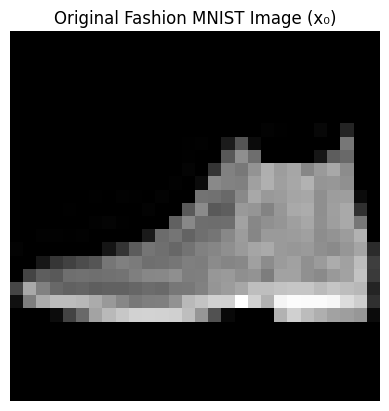

In [32]:
# 앞서 AE에서 준비한 Fashion MNIST 이미지를 사용합니다.
device = "cpu"  # 순확산 시각화만 수행하므로 GPU 불필요
x0_sample = torch.tensor(x_test[0]).permute(2, 0, 1).float()

plt.imshow(x0_sample.squeeze(), cmap='gray')
plt.axis('off')
plt.title("Original Fashion MNIST Image (x₀)")
plt.show()

In [34]:
T = 300  # total diffusion steps
beta = torch.linspace(1e-4, 0.02, T).to(device)
alpha = 1 - beta
alpha_bar = torch.cumprod(alpha, dim=0)

# 배치 단위로 노이즈 추가
def add_noise(x0, t):
    noise = torch.randn_like(x0)
    sqrt_ab = torch.sqrt(alpha_bar[t]).view(-1, 1, 1, 1)    # 원본데이터(x0)에 곱해지는 가중치
    sqrt_1_ab = torch.sqrt(1 - alpha_bar[t]).view(-1, 1, 1, 1)    # 노이즈(noise)에 곱해지는 가중치
    return sqrt_ab * x0 + sqrt_1_ab *noise   # 가중치에 원본데이터와 노이즈를 곱해줍시다!

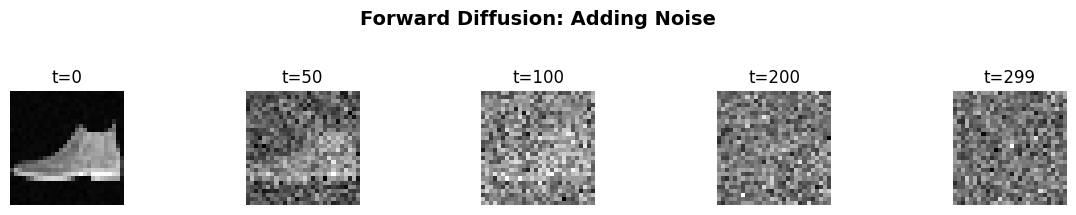

In [35]:
# 순확산 시각화 (샘플 한 장)
x0 = x0_sample.unsqueeze(0).to(device)  # [1,1,28,28]
plt.figure(figsize=(12, 2))
for i, t in enumerate([0, 50, 100, 200, 299]):
    xt = add_noise(x0, torch.tensor([t], device=device))
    plt.subplot(1, 5, i + 1)
    plt.imshow(xt.squeeze().cpu(), cmap='gray')
    plt.axis('off')
    plt.title(f"t={t}")
plt.suptitle("Forward Diffusion: Adding Noise", y=1.05, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

#### Diffusion — 순확산 결과 해석

그림에서 `t`가 증가할수록 이미지가 어떻게 변화하나요? 이 결과가 순확산에 해당하는 이유와, 새로운 이미지를 생성하기 위해 역확산에서 추가로 필요한 과정을 설명하세요.

**[답안]**
t가 증가할수록 이미지에 노이즈가 더해져 흐릿해진다. 순확산은 노이즈를 추가해 역확산 과정에서 노이즈를 제거하는 방법을 학습할 수 있도록 하는 과정이기 때문에 이는 순확산에 해당한다. 새로운 이미지를 생성하기 위해서는 역확산에서 노이즈를 예측하도록 학습된 신경망이 필요하다. 무작위 노이즈에서 시작해 이 신경망이 예측한 노이즈를 조금씩 제거하는 과정을 반복하면 새로운 이미지가 생성된다.


## 수고하셨습니다!